# ThinkPath: eksperimen validasi dan kalibrasi

Folder ini **bukan** tempat melatih detektor dari nol. Riset lintas-dataset menunjukkan model terlatih
anjlok begitu bertemu konteks baru, dan tidak ada korpus jawaban esai Indonesia berlabel Bloom di mana
pun. Produksi tetap memakai rantai LLM dan heuristik.

Yang dikerjakan di sini adalah membayar utang kejujuran: seluruh bobot dan ambang di
`backend/apps/analysis/engines/` (`ai_score.py`, `bloom.py`, `process_signals.py`) semula ditetapkan dari
penalaran, bukan dari data. Uji cepat pada esai akademik tulisan manusia pernah menghasilkan skor 77 dan
masuk band tinggi, yaitu tuduhan palsu. Notebook-notebook ini tempat masalah seperti itu ditemukan dan
diperbaiki, **berurutan**, dari data sampai keputusan.

Semua notebook memanggil kode produksi asli dari `backend/apps/analysis`, bukan salinannya, jadi laporan
tidak pernah basi diam-diam ketika kode produksi berubah.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import config

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)
config.ensure_dirs()
GOLD = config.GOLD_DIR / "gold_set.csv"

## Alur bertahap

Setiap tahap menjawab satu pertanyaan, dan hasilnya menjadi masukan tahap berikutnya.

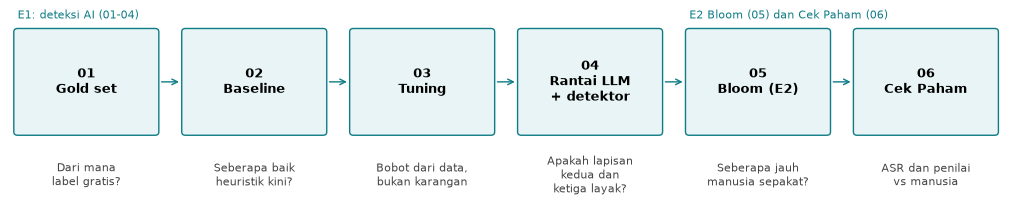

In [2]:
from matplotlib.patches import FancyBboxPatch

tahap = [
    ("01\nGold set", "Dari mana\nlabel gratis?"),
    ("02\nBaseline", "Seberapa baik\nheuristik kini?"),
    ("03\nTuning", "Bobot dari data,\nbukan karangan"),
    ("04\nRantai LLM\n+ detektor", "Apakah lapisan\nkedua dan\nketiga layak?"),
    ("05\nBloom (E2)", "Seberapa jauh\nmanusia sepakat?"),
    ("06\nCek Paham", "ASR dan penilai\nvs manusia"),
]
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.set_xlim(0, len(tahap) * 2.2)
ax.set_ylim(0, 3)
ax.axis("off")
for i, (judul, tanya) in enumerate(tahap):
    x = i * 2.2 + 0.1
    ax.add_patch(FancyBboxPatch((x, 1.2), 1.8, 1.5, boxstyle="round,pad=0.05", fc="#E8F4F5", ec="#0E7C86"))
    ax.text(x + 0.9, 1.95, judul, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.text(x + 0.9, 0.55, tanya, ha="center", va="center", fontsize=8, color="#444")
    if i < len(tahap) - 1:
        ax.annotate("", xy=(x + 2.15, 1.95), xytext=(x + 1.85, 1.95), arrowprops=dict(arrowstyle="->", color="#0E7C86"))
ax.text(0.1, 2.9, "E1: deteksi AI (01-04)", fontsize=8, color="#0E7C86")
ax.text(4 * 2.2 + 0.1, 2.9, "E2 Bloom (05) dan Cek Paham (06)", fontsize=8, color="#0E7C86")
plt.show()

| Notebook | Pertanyaan | Keluaran |
|---|---|---|
| `01_gold_set` | Bagaimana memperoleh label manusia vs AI tanpa anotator, dan jebakan apa yang harus dijaga? | `data/gold/gold_set.csv` |
| `02_baseline_heuristik` | Seberapa baik skor produksi memisahkan manusia dan AI, dan berapa mahasiswa jujur yang tertuduh? | ROC-AUC, FPR, ambang aman, diagnosis per sinyal |
| `03_tuning_bobot` | Bobot lima sinyal teks yang dicari dari data, dengan protokol yang tidak membocorkan test | bobot dan ambang band baru |
| `04_rantai_llm_dan_detektor` | Apakah lapisan Groq dan detektor berbayar mengungguli heuristik pada subset yang sama? | keputusan memakai atau mencabut lapisan |
| `05_validasi_bloom` | Seberapa jauh dua manusia sepakat, dan seberapa dekat mesin ke langit-langit itu? | kappa, matriks konfusi |
| `06_cekpaham_asr_dan_penilai` | Model ASR mana yang layak, dan apakah penilai LLM sepakat dengan manusia? | WER, kappa, uji injeksi |

## Status: apa yang sudah bisa dijalankan

Notebook ini memeriksa prasyarat tiap tahap. Tahap yang butuh data, kunci API, atau label manusia
**melewati dirinya sendiri** dengan pesan jelas bila prasyaratnya belum ada, bukan gagal di tengah.

In [3]:
def baris(path):
    return sum(1 for _ in path.open(encoding="utf-8")) if path.exists() else 0

def ada(path):
    return path.exists() and any(path.iterdir()) if path.is_dir() else path.exists()

labels_dir = config.DATA_DIR / "labels"
status = pd.DataFrame(
    [
        ("01 sisi manusia", "internet (OpenAlex, tanpa kunci)", baris(config.HUMAN_CACHE) > 0, f"{baris(config.HUMAN_CACHE)} abstrak di cache"),
        ("01 sisi AI", "GROQ_API_KEY", bool(config.GROQ_API_KEY) and baris(config.AI_CACHE) > 0, f"{baris(config.AI_CACHE)} teks AI di cache"),
        ("02-04 evaluasi E1", "gold_set.csv (manusia + AI)", GOLD.exists(), str(GOLD.relative_to(ROOT)) if GOLD.exists() else "belum dibangun"),
        ("04 lapisan Groq", "GROQ_API_KEY + gold set", bool(config.GROQ_API_KEY) and GOLD.exists(), "kunci " + ("terisi" if config.GROQ_API_KEY else "kosong")),
        ("04 detektor berbayar", "WINSTON_API_KEY + gold set", bool(config.detector_api_key()) and GOLD.exists(), "kunci " + ("terisi" if config.detector_api_key() else "kosong")),
        ("05 Bloom", "dua CSV penilai di data/labels/", labels_dir.exists() and len(list(labels_dir.glob("*.csv"))) >= 2, "label manusia belum ada" if not labels_dir.exists() else f"{len(list(labels_dir.glob('*.csv')))} CSV"),
        ("06 ASR", "data/asr_clips/manifest.csv + audio", (config.ASR_CLIPS_DIR / "manifest.csv").exists(), "rekaman klip belum ada"),
        ("06 penilai Cek Paham", "data/cekpaham_gold/sessions.jsonl", (config.JUDGE_GOLD_DIR / "sessions.jsonl").exists(), "sesi berlabel belum ada"),
    ],
    columns=["tahap", "prasyarat", "siap", "keterangan"],
)
status["siap"] = status["siap"].map({True: "siap", False: "belum"})
status

,tahap,prasyarat,siap,keterangan
0,01 sisi manusia,"internet (OpenAlex, tanpa kunci)",siap,60 abstrak di cache
1,01 sisi AI,GROQ_API_KEY,belum,0 teks AI di cache
2,02-04 evaluasi E1,gold_set.csv (manusia + AI),belum,belum dibangun
3,04 lapisan Groq,GROQ_API_KEY + gold set,belum,kunci kosong
4,04 detektor berbayar,WINSTON_API_KEY + gold set,belum,kunci kosong
5,05 Bloom,dua CSV penilai di data/labels/,belum,label manusia belum ada
6,06 ASR,data/asr_clips/manifest.csv + audio,belum,rekaman klip belum ada
7,06 penilai Cek Paham,data/cekpaham_gold/sessions.jsonl,belum,sesi berlabel belum ada


## Hasil yang pernah tercatat

Angka berikut **dipindahkan dari README lama**, bukan dihitung ulang di notebook ini (gold set dan
cache-nya tidak ikut repo: ukurannya besar dan bisa dibangun ulang). Jalankan notebook 01 sampai 03 untuk
mereproduksinya. Semuanya diukur pada **abstrak akademik** berbahasa Indonesia, bukan esai mahasiswa.

| Tanggal | Tahap | Hasil |
|---|---|---|
| 17 Agu 2026 | 02 baseline → 03 tuning | AUC test 0,884 → **0,912** (set penuh 0,869 → 0,901) |
| 17 Agu 2026 | 03 tuning | ambang band `mid` 56 → **42**; recall 0,489 → 0,607 dengan FPR tetap di bawah 5% |
| sebelum tuning | 02 baseline | FPR 0,838 pada ambang lama: sebagian besar teks manusia tertuduh |
| uji jalan awal (24 sampel) | 02 baseline | `impersonality` mati; `mechanical_polish` ternyata sinyal terkuat, membantah dugaan awal |
| belum diukur | 04 | lapisan Groq, dan detektor Winston pada teks Indonesia |
| belum diukur | 05 | akurasi E2 Bloom (butuh label manusia) |

> **Batasan yang wajib ditulis di naskah.** Abstrak ilmiah bukan esai tugas mahasiswa: registernya lebih
> formal dan strukturnya lebih baku. Set ini sah untuk mengukur apakah sinyal bekerja pada teks akademik
> Indonesia, tetapi angkanya tidak boleh diklaim berlaku untuk jawaban tugas tanpa uji lanjutan. Sisi AI
> seluruhnya dari model yang dilayani Groq; menambah generator keluarga lain akan memperkuat kesimpulan.

## Prinsip yang dijaga di semua tahap

1. **Subset yang sama untuk perbandingan.** Mengukur mesin A di 40 sampel lalu membandingkannya dengan
   mesin B di 999 sampel adalah perbandingan yang tidak sah.
2. **Test tidak disentuh saat mencari.** Hanya angka test yang boleh dikutip.
3. **FPR lebih penting daripada recall.** Recall tinggi tidak ada artinya bila harganya menuduh mahasiswa
   jujur. Ambang dipilih dari batas FPR 5%, bukan karena angkanya bulat.
4. **Cache menyimpan semua skor berbayar** (kunci memuat nama model dan versi), jadi tahap yang dicicil
   lintas hari tidak membayar dua kali.
5. **Bila hasil menunjukkan lapisan tidak berguna, cabut lapisannya**, jangan menggeser ambang sampai
   angkanya tampak bagus.